# The amount of information available to the mouse correlates inversely with infotaxis behavior.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
cd "/app/"

/app


In [3]:
%run env.py
%run run.py connect

/opt/conda/lib/python3.11/site-packages/datajoint/settings.py:1039: UserWarning: No datajoint.json found. Using defaults and environment variables. Run `dj.config.save_template()` to create a template configuration.
  config = _create_config()


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from vr4mice.analysis import plotting
from vr4mice.schema import base_analysis
from vr4mice.analysis.analysis import style
from vr4mice.schema.interpolated_trajectories import InterpolatedTrials
from vr4mice.schema.decision import InclusionStatus, ExperimentMember, LabelSet, Label, PredictionModel10Windows, DecisionPoints10Windows

from statsmodels.stats.anova import AnovaRM
import scipy.stats as stats
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from vr4mice.analysis import regression

from scipy.stats import pearsonr
from mpl_toolkits.axes_grid1 import make_axes_locatable

from vr4mice.analysis.stats import get_multi_p_values_global, get_multi_p_values_binned, plot_aperture_heatmap

style()

save_fig_path = "notebooks/NP_figures/NP_figures/NP_"

In [5]:
task_type_key = {"set_name": "contrast_white_target",
                 "stage_name": "multi_occlusion",}

BATCH_NAME = "batch2"

In [6]:
sessions_list = list(
                (InclusionStatus * ExperimentMember & {"included": 1} & task_type_key & {"batch_name": BATCH_NAME}).fetch(
                    "dataset"
                )
            )

len(sessions_list)

/tmp/ipykernel_83567/1882034823.py:2: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  (InclusionStatus * ExperimentMember & {"included": 1} & task_type_key & {"batch_name": BATCH_NAME}).fetch(


6

In [7]:
# This takes a while to fetch because we need to fetch data for all trials
dataset_list = []
for d in sessions_list:
    print(d)
    try:
        dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))
    except Exception as err:
        print(err, " dataset missing")
interpolated_df = pd.concat(dataset_list)
interpolated_df["mouse_name"] = interpolated_df.dataset.str.split("_").str[0]

/tmp/ipykernel_83567/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Xestia_2026-08-03_1
Xestia_2026-08-04_1


/tmp/ipykernel_83567/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Xestia_2026-08-05_1


/tmp/ipykernel_83567/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Yurumi_2026-08-05_1


/tmp/ipykernel_83567/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Yurumi_2026-08-06_1


/tmp/ipykernel_83567/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


Yurumi_2026-08-07_1


/tmp/ipykernel_83567/2634139630.py:6: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  dataset_list.append(pd.DataFrame((InterpolatedTrials() & f'dataset = "{d}"').fetch(as_dict=True)[0]))


In [8]:
box_df = base_analysis.BoxDataFrame().get_data(key={"dataset": "Pheasant_2024-08-15_2"})

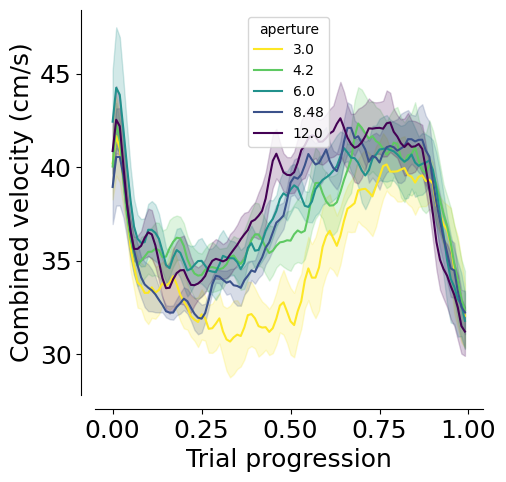

In [9]:
fig, ax = plt.subplots(1, 1, figsize=(5, 5))
ax = ax
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_length"], as_index=False
).mean(numeric_only=True)

mean_mouse.sort_values("aperture", inplace=True)
mean_mouse["aperture"] = mean_mouse.aperture.astype("str")

sns.lineplot(
    data=mean_mouse,
    x="trial_length",
    y="velocity",
    palette=plotting.colors_multi_aperture,
    hue="aperture",
    errorbar="se",
    ax=ax,
)

sns.despine(offset=10)
ax.set_xlabel("Trial progression")
ax.set_ylabel("Combined velocity (cm/s)")
plt.savefig(save_fig_path + "figure5_velocity.svg", transparent=False)

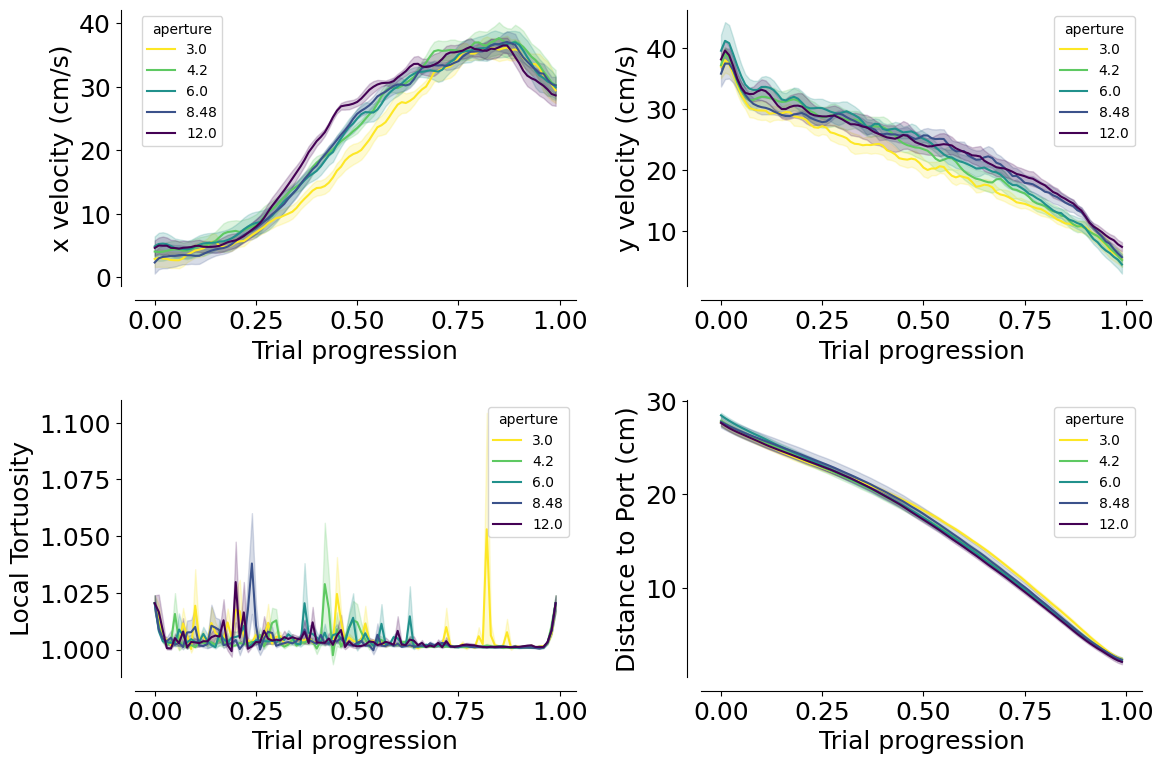

In [10]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

for (i, label), label_str in zip(enumerate(
    ["velocity_x_fliped", "velocity_y", "local_tortuosity", "distance_to_choice"]
), ["x velocity (cm/s)", "y velocity (cm/s)", "Local Tortuosity", "Distance to Port (cm)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=(
            plotting.colors_aperture[:2]
            if len(mean_mouse.aperture.unique()) == 2
            else plotting.colors_multi_aperture
        ),
        hue="aperture",
        errorbar="se",
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)
    
plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure5_velocity_tortuosity_distance.svg", bbox_inches="tight", transparent=True)

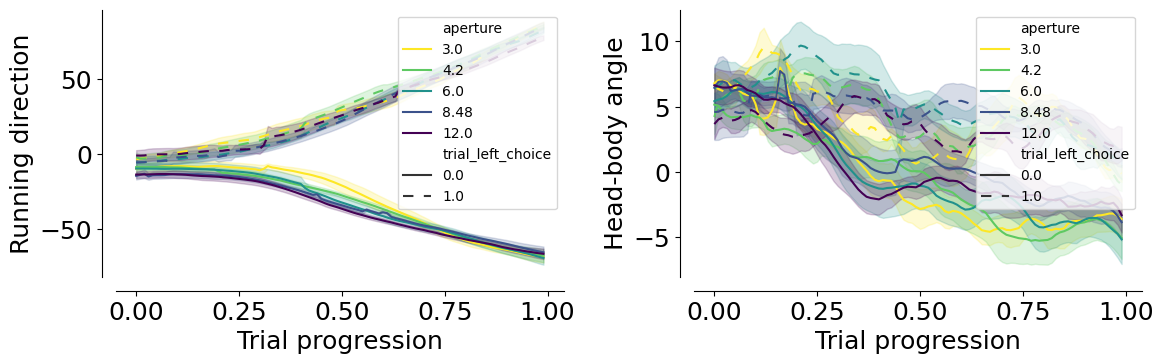

In [11]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax = ax.flatten()

dash_styles = {
    mean_mouse.trial_left_choice.unique()[0]: "",         # Solid
    mean_mouse.trial_left_choice.unique()[1]: (5, 5)      # Dashed
}

for (i, label), label_str in zip(enumerate(["heading_dir", "head_angle"]), 
                                 ["Running direction", "Head-body angle"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=plotting.colors_choice[::-1]
        if len(mean_mouse.aperture.unique()) == 2
        else plotting.colors_multi_aperture,
        hue="trial_left_choice"
        if len(mean_mouse.aperture.unique()) == 2
        else "aperture",
        style=(
            "aperture"
            if len(mean_mouse.aperture.unique()) == 2
            else "trial_left_choice"
        ),
        dashes=dash_styles,
        errorbar="se",
        ax=ax[i],
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)


plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure5_heading_dir_head_angle.svg", bbox_inches="tight", transparent=True)

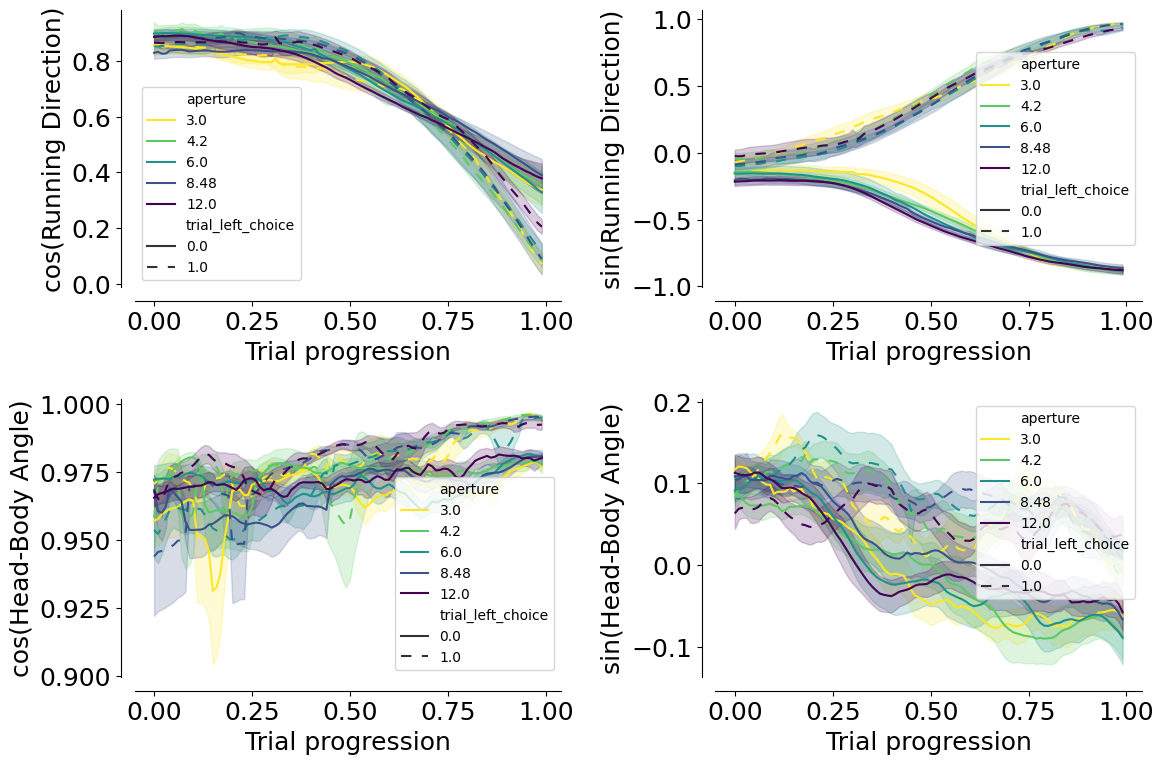

In [12]:
mean_mouse = interpolated_df.groupby(
    ["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False
).mean(numeric_only=True)

fig, ax = plt.subplots(2, 2, figsize=(12, 8))
ax = ax.flatten()

dash_styles = {
    mean_mouse.trial_left_choice.unique()[0]: "",         # Solid
    mean_mouse.trial_left_choice.unique()[1]: (5, 5)      # Dashed
}

for (i, label), label_str in zip(enumerate(
    ["heading_dir_cos", "heading_dir_sin", "head_angle_cos", "head_angle_sin"]
), ["cos(Running Direction)", "sin(Running Direction)", "cos(Head-Body Angle)", "sin(Head-Body Angle)"]):
    sns.lineplot(
        data=mean_mouse,
        x="trial_length",
        y=label,
        palette=plotting.colors_choice[::-1]
        if len(mean_mouse.aperture.unique()) == 2
        else plotting.colors_multi_aperture,
        hue="trial_left_choice"
        if len(mean_mouse.aperture.unique()) == 2
        else "aperture",
        style=(
            "aperture"
            if len(mean_mouse.aperture.unique()) == 2
            else "trial_left_choice"
        ),
        errorbar="se",
        ax=ax[i],
        dashes=dash_styles,
    )
    ax[i].set_ylabel(label_str)
    ax[i].set_xlabel("Trial progression")
    sns.despine(ax=ax[i], offset=10)


plt.tight_layout(pad=2)
plt.savefig(save_fig_path + "figure5_heading_dir_head_angle_cos_sin.svg", bbox_inches="tight", transparent=True)

In [13]:
interpolated_df["mouse_name"] = interpolated_df.dataset.str.split("_").str [0]

optimal_df =  interpolated_df.groupby(["dataset", "mouse_name", "trial", "aperture"], as_index=False).mean()
optimal_df =  interpolated_df.groupby(["dataset", "mouse_name", "aperture"], as_index=False).mean()

In [14]:
optimal_df["lab_id"] = 0
for dataset_name in sessions_list:
    # Fetch lab_id for each dataset
    optimal_df.loc[optimal_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]

/tmp/ipykernel_83567/3761630674.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  optimal_df.loc[optimal_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_83567/3761630674.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  optimal_df.loc[optimal_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_83567/3761630674.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  optimal_df.loc[optimal_df.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_83567/3761630674.py:4: DeprecationWarning: fetch() is depreca

                Anova
         F Value Num DF  Den DF Pr > F
--------------------------------------
aperture  0.7606 4.0000 20.0000 0.5631



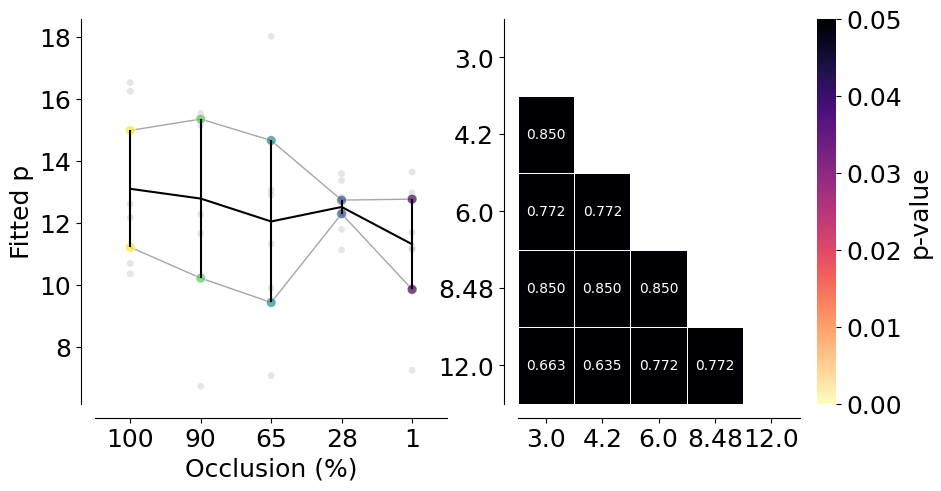

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

counts = (
    optimal_df
    .groupby(["mouse_name", "dataset", "aperture"], as_index=False)
    .optimal_p.mean()
)

counts["count"] = counts["optimal_p"]
counts = pd.DataFrame(counts.reset_index())
counts.aperture = counts.aperture.round(2).astype(str)

plotting._plot_bar_counts(
    counts=counts,
    label_x="aperture",
    alpha=0.2,
    ax=ax[0],
    per_mouse=True,
    cmap=plotting.colors_multi_aperture,
)
ax[0].invert_xaxis()

ax[0].set_xlabel("Occlusion (%)")
ax[0].set_ylabel("Fitted p")
ax[0].set_xlim(-0.5, 4.5)
ax[0].set_xticks([0, 1, 2, 3, 4], ["100", "90", "65", "28", "1"])
plt.legend([], [], frameon=False)
sns.despine(offset=10, ax=ax[0])

p_values = get_multi_p_values_global(optimal_df, y_var="optimal_p")
plot_aperture_heatmap(p_values, ax= ax[1])
sns.despine(offset=10, ax=ax[1])

print(AnovaRM(counts, depvar="count", subject="dataset", within=["aperture"]).fit())
plt.savefig(save_fig_path + "figure5_fitted_p.svg", transparent=True)

                Anova
         F Value Num DF  Den DF Pr > F
--------------------------------------
aperture  0.7606 4.0000 20.0000 0.5631



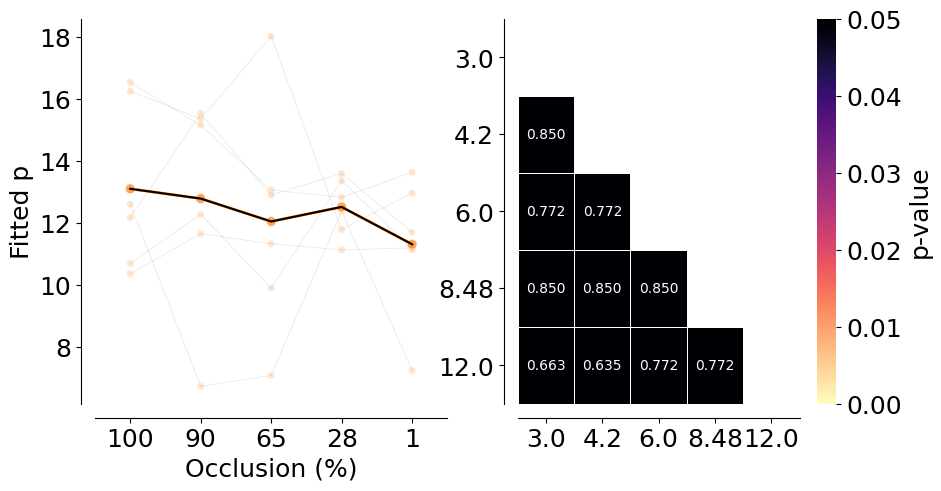

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 5))

counts = (
    optimal_df
    .groupby(["lab_id", "dataset", "aperture"], as_index=False)
    .optimal_p.mean()
)

counts["count"] = counts["optimal_p"]
counts = pd.DataFrame(counts.reset_index())
counts.aperture = counts.aperture.round(2).astype(str)

plotting._plot_bar_counts(
    counts=counts,
    label_x="aperture",
    alpha=0.2,
    ax=ax[0],
    per_lab=True,
    cmap=plotting.colors_multi_aperture,
)
ax[0].invert_xaxis()

ax[0].set_xlabel("Occlusion (%)")
ax[0].set_ylabel("Fitted p")
ax[0].set_xlim(-0.5, 4.5)

ax[0].set_xticks([0, 1, 2, 3, 4], ["100", "90", "65", "28", "1"])
plt.legend([], [], frameon=False)
sns.despine(offset=10, ax=ax[0])

p_values = get_multi_p_values_global(optimal_df,  y_var="optimal_p")
plot_aperture_heatmap(p_values, ax= ax[1])

sns.despine(offset=10, ax=ax[1])

print(AnovaRM(counts, depvar="count", subject="dataset", within=["aperture"]).fit())
plt.savefig(
    save_fig_path + "figure5_fitted_p_per_lab.svg",
    transparent=True,
)

## Prediction model

In [17]:
model_key = {"label_set_id": 8, "params_id": 1}

/tmp/ipykernel_83567/140088111.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  coefs = (PredictionModel10Windows() & task_type_key & model_key).fetch("coefficients_by_window")[0]
/tmp/ipykernel_83567/140088111.py:2: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  model_labels, clean_labels = (LabelSet.Member * Label & model_key).fetch("label_key", "clean_name")


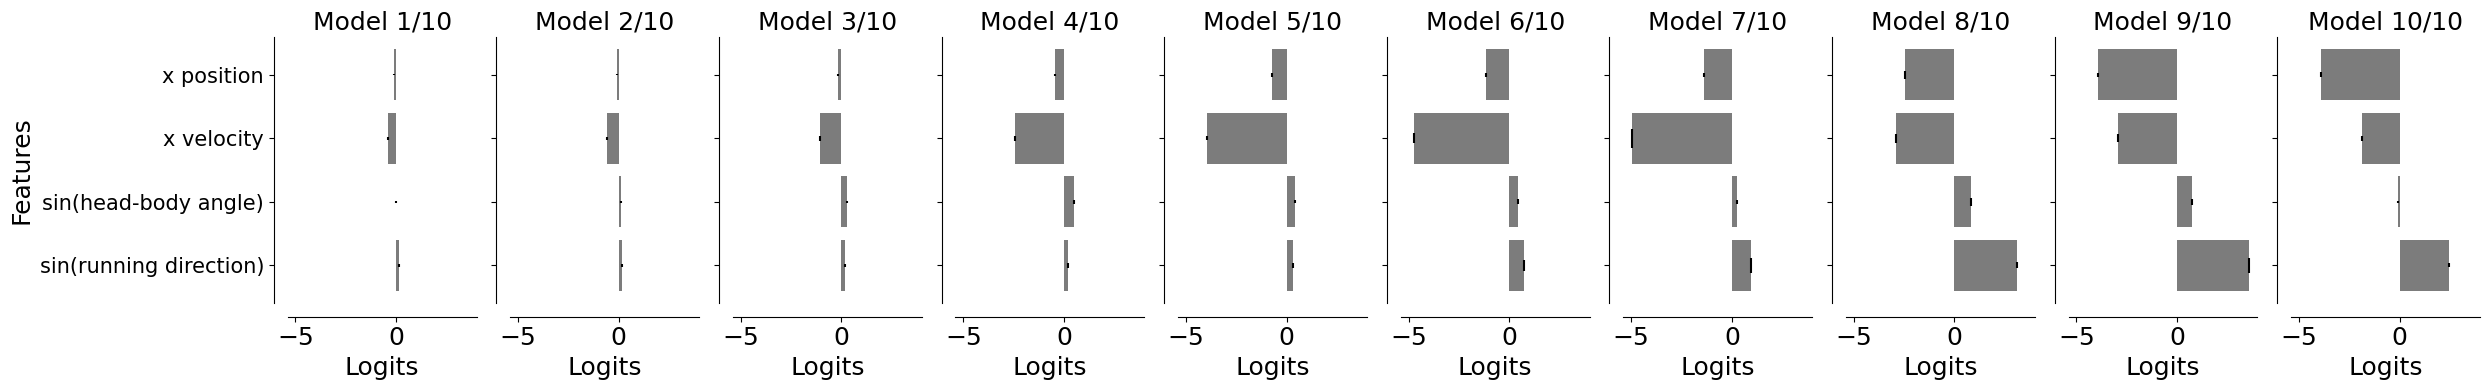

In [18]:
coefs = (PredictionModel10Windows() & task_type_key & model_key).fetch("coefficients_by_window")[0]
model_labels, clean_labels = (LabelSet.Member * Label & model_key).fetch("label_key", "clean_name")

fig, ax = plt.subplots(1, 10, figsize=(25, 4), sharey=True, sharex=True)
ax = ax.flatten()
for axis, key in zip(ax, coefs.keys()):
    
    axis.barh(
        model_labels,
        np.mean(coefs[key][:, 1:], axis=0),
        yerr=stats.sem(coefs[key][:, 1:], axis=0),
        color="#7C7C7C",
    )
    sns.despine(offset=10, ax=axis)

    axis.set_yticks(np.arange(len(model_labels)))
    axis.set_yticklabels(clean_labels, rotation=0, ha="right", fontsize=15)
    axis.set_xlabel("Logits")
    if key == 0:
        axis.set_ylabel("Features")
    else:
        axis.set_ylabel("")
    axis.set_title(f"Model {key+1}/10")
plt.tight_layout()

plt.savefig(
    save_fig_path + "figure5_model_logits.svg", transparent=False
)

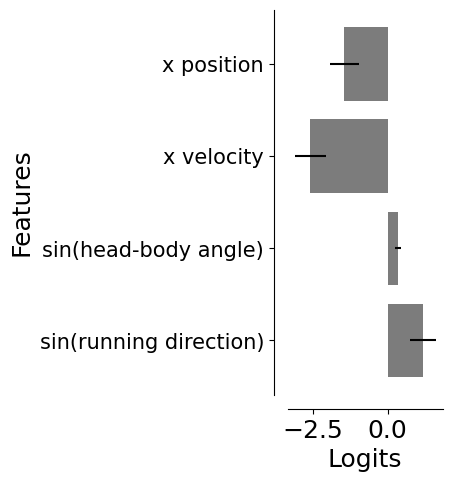

In [19]:
# Average across windows
mean_coef = np.array([np.mean(coefs[key], axis=0) for key in coefs.keys()])

fig, ax = plt.subplots(1, 1, figsize=(2, 5))
ax.barh(
    model_labels,
    np.mean(mean_coef[:, 1:], axis=0),
    xerr=stats.sem(mean_coef[:, 1:], axis=0), # sem across windows
    color="#7C7C7C",
)
sns.despine(offset=10, ax=ax)

ax.set_yticks(np.arange(len(model_labels)))
ax.set_yticklabels(clean_labels, rotation=0, ha="right", fontsize=15)
ax.set_xlabel("Logits")
ax.set_ylabel("Features")
plt.savefig(
    save_fig_path + "figure5_model_logits_average.svg", transparent=False
)

In [20]:
prediction_df = pd.DataFrame((PredictionModel10Windows().SessionPrediction() & model_key & task_type_key).fetch(
    "dataset", "trial", "proba_left", "accuracy", "trial_length", as_dict=True)).explode(["trial", "proba_left", "accuracy", "trial_length"])

/tmp/ipykernel_83567/1275284121.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  prediction_df = pd.DataFrame((PredictionModel10Windows().SessionPrediction() & model_key & task_type_key).fetch(


In [21]:
df_model = prediction_df.merge(
    interpolated_df[["dataset", "trial_length", "trial", "aperture", "trial_left_choice", "x", "y"]], on=["dataset", "trial", "trial_length"]
)

df_model["accuracy"] = df_model["accuracy"].astype(float)
df_model["proba_left"] = df_model["proba_left"].astype(float)

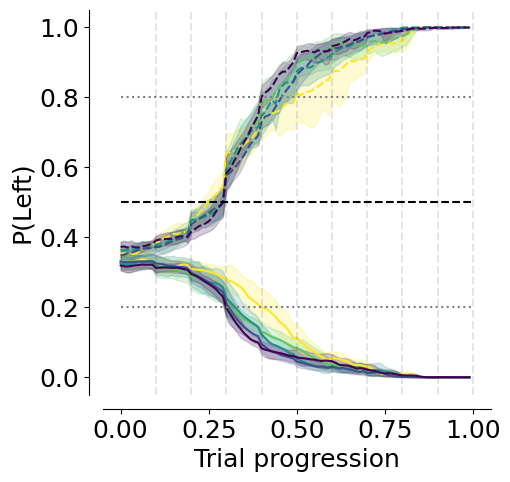

In [22]:
df_model_mean = df_model.groupby(["dataset", "aperture", "trial_left_choice", "trial_length"], as_index=False).mean(numeric_only=True)
fig, ax = plt.subplots(1, 1, figsize=(5, 5))

dash_styles = {
    df_model_mean.aperture.unique()[0]: "",         # Solid
    df_model_mean.aperture.unique()[1]: (5, 5)      # Dashed
}
    
sns.lineplot(
    data=df_model_mean,
    x="trial_length",
    y="proba_left",
    hue="aperture",
    style="trial_left_choice",
    palette=plotting.colors_multi_aperture,
    sort=False,
    alpha=1,
    ax=ax,
)

ax.hlines(0.5, xmin=0, xmax=1, colors="black", linestyles="dashed")
ax.hlines(0.8, xmin=0, xmax=1, colors="gray", linestyles="dotted")
ax.hlines(0.2, xmin=0, xmax=1, colors="gray", linestyles="dotted")
ax.set_ylabel("P(Left)")
ax.set_xlabel("Trial progression")

for i in range(10):
    plt.axvline((i+1)/10, color="k", linestyle="dashed", alpha=0.1)
    
    
sns.despine(offset=10)
plt.legend([], [], frameon=False)

plt.savefig(
    save_fig_path + "figure5_dynamic_decision_variable_mean.svg", transparent=True
)
plt.savefig(
    save_fig_path + "figure5_dynamic_decision_variable_mean.png", transparent=True, 
    dpi=300, bbox_inches="tight"
)

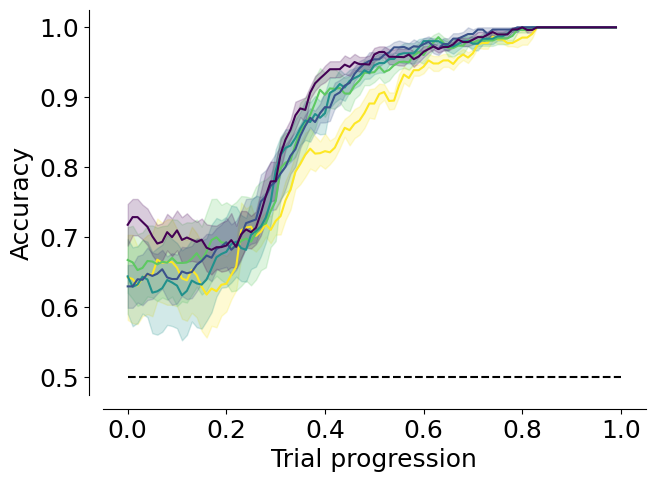

In [23]:
# Accuracy
df_model_mean =  df_model.groupby(["dataset", "aperture", "trial_length"], as_index=False).mean(numeric_only=True)

fig, ax = plt.subplots(1, 1, figsize=(7, 5))
sns.lineplot(
    ax=ax,
    data=df_model_mean,
    y="accuracy",
    x="trial_length",
    hue="aperture",
    palette=plotting.colors_multi_aperture,
    errorbar="se",
)
sns.despine(offset=10)
ax.set_xlabel("Trial progression")
ax.set_ylabel("Accuracy")
ax.hlines(0.5, 0, 1, color="black", linestyle="--")
plt.legend([], [], frameon=False)

plt.savefig(
    save_fig_path + "figure5_model_accuracy.svg", transparent=False
)

In [24]:
df_model["trial_length_bin"] = pd.cut(
    df_model["trial_length"], bins=50
)

df_anova = df_model.groupby(
    ["dataset", "aperture", "trial_length_bin"], as_index=False
).mean(numeric_only=True)

print(
    AnovaRM(
        data=df_anova,
        depvar="accuracy",
        subject="dataset",
        within=["aperture", "trial_length_bin"],
    ).fit()
)

                          Anova
                          F Value  Num DF   Den DF  Pr > F
----------------------------------------------------------
aperture                   1.9685   4.0000  20.0000 0.1383
trial_length_bin          66.8655  49.0000 245.0000 0.0000
aperture:trial_length_bin  0.9730 196.0000 980.0000 0.5877



## Get the decision points

In [25]:
decision_points = pd.DataFrame((DecisionPoints10Windows() & task_type_key & model_key & "threshold_uncertainty = 0.2").fetch(as_dict=True))
decision_points = decision_points.explode(["trial", "aperture", "trial_length", "trial_left_choice", "proba_left", "x", "y", "trial_rewarded"])
decision_points["mouse_name"] = decision_points.dataset.str.split("_").str[0]
decision_points["y"] = decision_points["y"].astype(float)

/tmp/ipykernel_83567/2344792741.py:1: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points = pd.DataFrame((DecisionPoints10Windows() & task_type_key & model_key & "threshold_uncertainty = 0.2").fetch(as_dict=True))


### Get distance to screen at decision point

In [26]:
decision_points["distance_to_screen"] = np.abs(decision_points["y"] - 27)

3.0-4.2: TtestResult(statistic=-0.5856424139757693, pvalue=0.5835511123595942, df=5)
 mean difference:  0.7348794382582042
3.0-6.0: TtestResult(statistic=-1.20916835649695, pvalue=0.28065004418100525, df=5)
 mean difference:  1.353900475960259
3.0-8.48: TtestResult(statistic=-3.1685243247956074, pvalue=0.024856057739583, df=5)
 mean difference:  2.2049943891155337
mean: 17.914077296753792 +/- 0.6591792004464179
4.2-6.0: TtestResult(statistic=-0.48684290456040985, pvalue=0.6469600420797899, df=5)
 mean difference:  0.6190210377020549
4.2-8.48: TtestResult(statistic=-1.5219793347667325, pvalue=0.18850419599389348, df=5)
 mean difference:  1.4701149508573295
mean: 18.648956735011996 +/- 0.8283335191965658
6.0-8.48: TtestResult(statistic=-1.1170387189417157, pvalue=0.3147597228657315, df=5)
 mean difference:  0.8510939131552746
mean: 19.26797777271405 +/- 0.6828787254338158
mean: 20.119071685869326 +/- 0.2569563009112475
12.0-3.0: TtestResult(statistic=2.451138738482641, pvalue=0.057855327

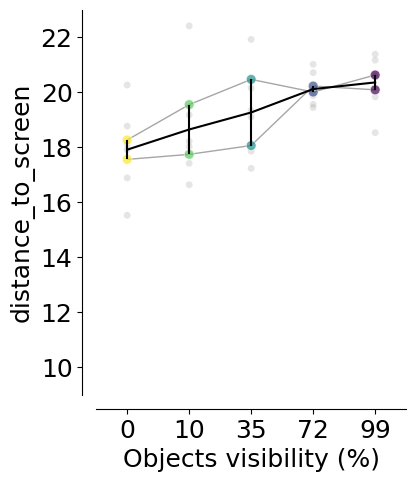

In [27]:
fig, ax = plt.subplots(1, 1, figsize=(4, 5))
_ = plotting.pairplot_average_decision_point(
    decision_points,
    label_parameter="distance_to_screen",
    ax=ax,
    cmap=plotting.colors_multi_aperture,
    per_mouse=True,
)
ax.set_xlabel("Objects visibility (%)")
ax.set_ylim(9, 23)
ax.set_xlim(-0.5, 4.5)
ax.set_xticks([0, 1, 2, 3, 4], ["0", "10", "35", "72", "99"])
plt.legend([], [], frameon=False)
sns.despine(offset=10)

plt.savefig(
    save_fig_path + "figure5_decision_points_distance.svg",
    transparent=True,
)

In [28]:
decision_points["lab_id"] = 0
for dataset_name in sessions_list:
    # Fetch lab_id for each dataset
    decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]

/tmp/ipykernel_83567/1189363056.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_83567/1189363056.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_83567/1189363056.py:4: DeprecationWarning: fetch() is deprecated in DataJoint 2.0. Use to_dicts(), to_pandas(), to_arrays(), or keys() instead.
  decision_points.loc[decision_points.dataset==dataset_name, "lab_id"] = ((vr4mice.Collab() & f'dataset = "{dataset_name}"') * vr4mice.Labs()).fetch("lab")[0]
/tmp/ipykernel_83567/1189363056.py:4: Deprecat

In [29]:
aperture_to_occlusion = {
    12.0: 99,
    8.48: 72,
    6.0: 35,
    4.2: 10,
    3.0: 0
}

3.0-4.2: TtestResult(statistic=0.6587023870706145, pvalue=0.539206294148765, df=5)
 mean difference:  -0.7348794382582042
3.0-6.0: TtestResult(statistic=1.395920617077752, pvalue=0.22155497105482405, df=5)
 mean difference:  -1.3539004759602564
3.0-8.48: TtestResult(statistic=2.8791355703422212, pvalue=0.03462302288130747, df=5)
 mean difference:  -2.2049943891155293
mean: 9.085922703246206 +/- 0.659179200446418
4.2-6.0: TtestResult(statistic=0.7824316558276773, pvalue=0.4693767355131794, df=5)
 mean difference:  -0.6190210377020522
4.2-8.48: TtestResult(statistic=1.5809060764270573, pvalue=0.174740180399103, df=5)
 mean difference:  -1.470114950857325
mean: 8.351043264988002 +/- 0.8283335191965661
6.0-8.48: TtestResult(statistic=1.0473740853634104, pvalue=0.342893482086365, df=5)
 mean difference:  -0.8510939131552728
mean: 7.73202222728595 +/- 0.6828787254338156
mean: 6.880928314130677 +/- 0.2569563009112474
12.0-3.0: TtestResult(statistic=-4.050280006790784, pvalue=0.009822666426038

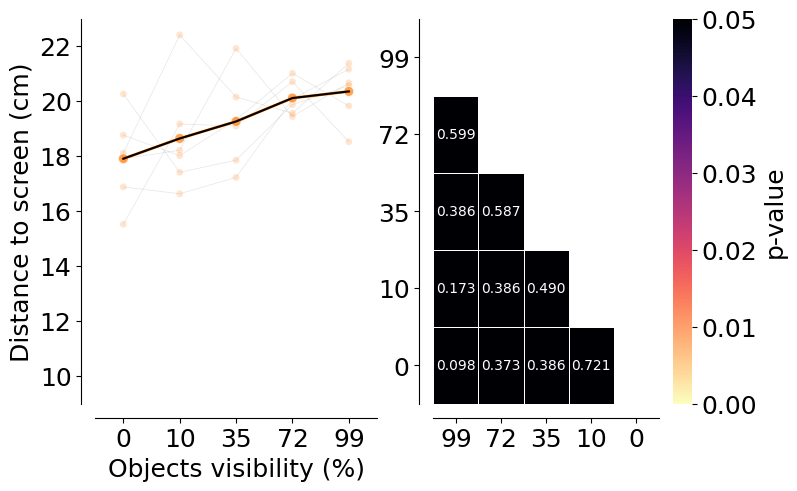

In [30]:
fig, ax = plt.subplots(1, 2, figsize=(8, 5))

_ = plotting.pairplot_average_decision_point(
    decision_points,
    label_parameter="y",
    ax=ax[0],
    cmap=plotting.colors_multi_aperture,
    per_lab=True,
)
ax[0].set_ylim(9, 23)
ax[0].set_xlim(-0.5, 4.5)
ax[0].set_xticks([0, 1, 2, 3, 4], ["0", "10", "35", "72", "99"])
plt.legend([], [], frameon=False)
ax[0].set_xlabel("Objects visibility (%)")
sns.despine(offset=10, ax=ax[0])

p_values = get_multi_p_values_global(decision_points,  y_var="y")
plot_aperture_heatmap(p_values, ax= ax[1])
ax[1].set_xticks([0.5, 1.5, 2.5, 3.5, 4.5], ["99", "72", "35", "10", "0"])
ax[1].set_yticks([0.5, 1.5, 2.5, 3.5, 4.5], ["99", "72", "35", "10", "0"])
ax[1].set_yticklabels(ax[1].get_yticklabels(), rotation=90)
sns.despine(offset=10, ax=ax[1])

decision_points_anova = decision_points.groupby(["dataset", "aperture"], as_index=False)[
    "y"
].mean()
print(AnovaRM(decision_points_anova, depvar="y", subject="dataset", within=["aperture"]).fit())


plt.savefig(
    save_fig_path + "figure5_decision_points_distance_per_lab.svg",
    transparent=True,
)

In [31]:
from vr4mice.schema.information_maps import InformationMap

# Each multi-occluder task aperture has its own info map
info_maps = InformationMap() & [{"game_aperture": ap} for ap in aperture_to_occlusion]

# normalize across all maps to max 1
max_value = info_maps.max_info()

/tmp/ipykernel_83567/794615952.py:19: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  base_cmap = cm.get_cmap("PuOr")


game_aperture=3 | visible_percent=0% | infomap_aperture=8.7
game_aperture=4.2 | visible_percent=10% | infomap_aperture=12.3
game_aperture=6 | visible_percent=35% | infomap_aperture=17.3
game_aperture=8.48 | visible_percent=72% | infomap_aperture=24.5
game_aperture=12 | visible_percent=99% | infomap_aperture=34.6


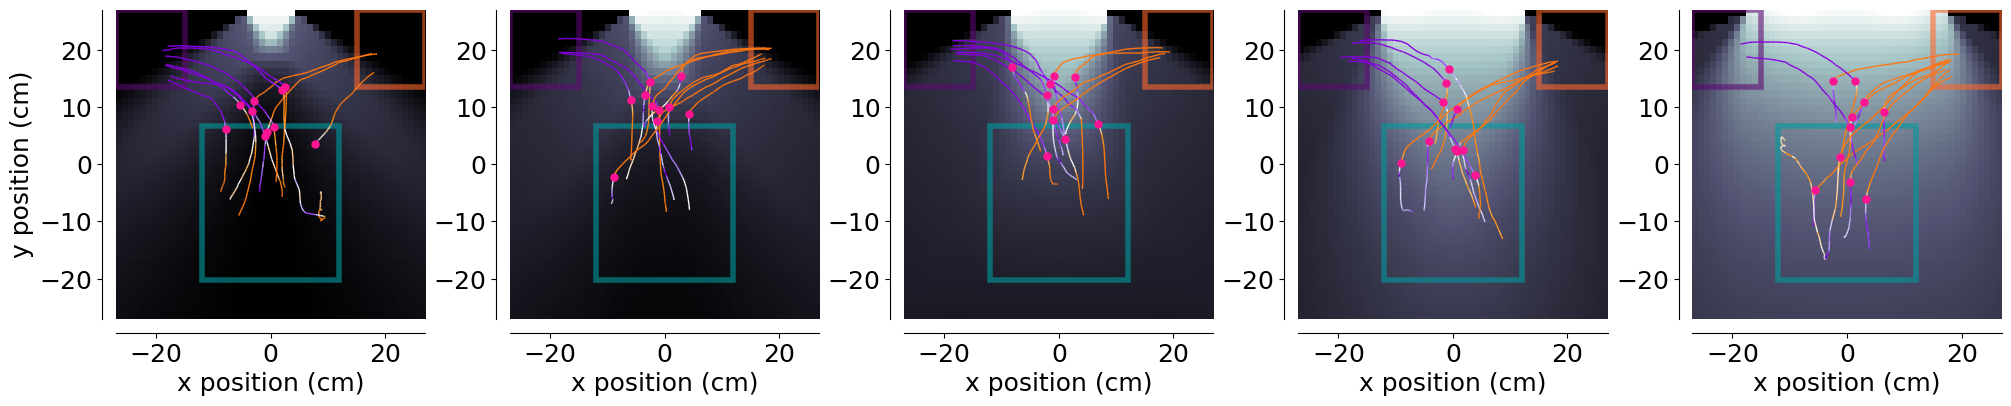

In [32]:
fig, ax = plt.subplots(
    1, len(df_model.aperture.unique()), figsize=(20, 4), constrained_layout=True,
)

decision_color = "deeppink"
session_to_plot = "Yurumi_2026-08-07_1"

# Pick 15 trials for each condition randomly (fixed seed for reproducibility)
np.random.seed(0)
trials = []
for aperture in sorted(df_model.aperture.unique()):
    ap_trials = df_model[
        (df_model.dataset == session_to_plot) & (df_model.aperture == aperture)
    ]["trial"].unique()
    selected_trials = np.random.choice(ap_trials, size=10, replace=False)
    trials.extend(selected_trials)

# Start from PuOr
base_cmap = cm.get_cmap("PuOr")

# Make a brighter version by rescaling luminance
def brighten(cmap, factor=3):
    colors = cmap(np.linspace(0, 1, 256))
    rgb = mcolors.rgb_to_hsv(colors[:, :3])
    rgb[:, 2] = rgb[:, 2] * factor  # brighten value channel
    rgb[:, 2] = np.clip(rgb[:, 2], 0, 1)
    colors[:, :3] = mcolors.hsv_to_rgb(rgb)
    return mcolors.ListedColormap(colors)

bright_puor = brighten(base_cmap)

for i, aperture in enumerate(sorted(df_model.aperture.unique())):
    regression.plot_decision_points_on_trajectory(
        df_model[
            (df_model.dataset == session_to_plot) & (df_model.aperture == aperture)
        ],
        box_df,
        decision_point=decision_points[
            (decision_points.dataset == session_to_plot)
            & (decision_points.aperture == aperture)
        ],
        color=decision_color,
        trials=trials,
        ax=ax[i],
        cmap=bright_puor,
    )

    info_maps.plot(
        game_aperture=float(aperture),
        ax=ax[i],
        normalize_by=max_value,
        rig_coordinates=True,
        title=False,
        colorbar=False,
        cmap="bone",
        zorder=-10,
    )
    
    ax[i].set_xlim(-27, 27)
    ax[i].set_ylim(-27, 27)
    #ax[i].set_aspect(1.4)
    ax[i].set_xlabel("x position (cm)")
    ax[i].set_ylabel("")
    #ax[i].set_title(f"Aperture {aperture_to_occlusion[aperture]}%")
    sns.despine(offset=10, ax=ax[i])

ax[0].set_ylabel("y position (cm)")
plt.savefig(
    save_fig_path + "figure5_decision_points_trajectories_bright.svg",
    transparent=True,
)

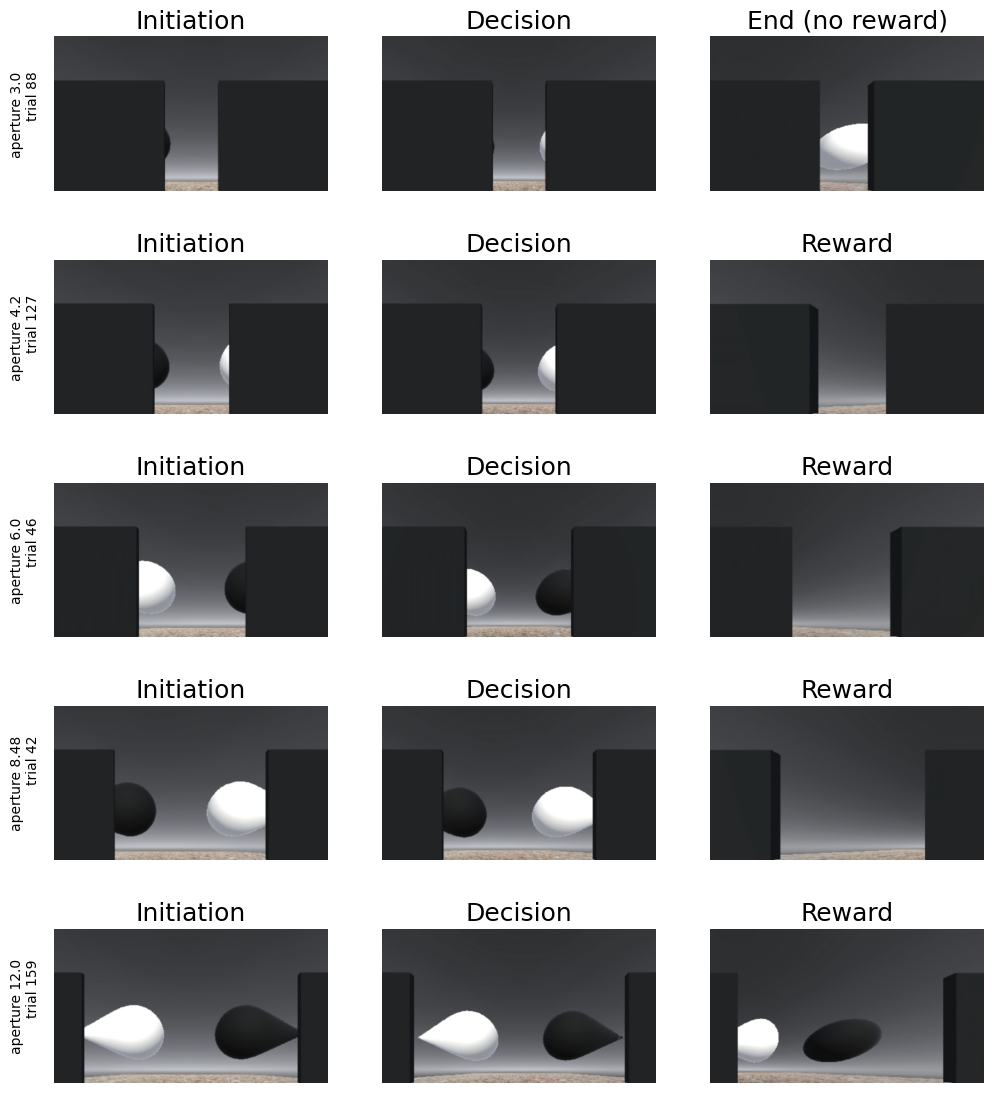

In [33]:
from vr4mice.schema.inputs_videos import StepVideoFrame


def decision_xy(decision_points, dataset, trial):
    """(x, y) of a trial's decision point, None if it has none."""
    dp = decision_points[(decision_points.dataset == dataset) & (decision_points.trial == trial)]
    return (float(dp.x.iloc[0]), float(dp.y.iloc[0])) if len(dp) else None


# Input video frames displayed at initiation, decision and reward: one plotted trial per aperture
apertures = sorted(df_model.aperture.unique())
session_trials = df_model[df_model.dataset == session_to_plot][["trial", "aperture"]].drop_duplicates()

fig, axes = plt.subplots(len(apertures), 3, figsize=(12, 2.8 * len(apertures)))
for row_axes, aperture in zip(np.atleast_2d(axes), apertures):
    for ax in row_axes:
        ax.axis("off")
    aperture_trials = set(session_trials[session_trials.aperture == aperture].trial)
    trial = int(next(t for t in trials if t in aperture_trials))
    StepVideoFrame.plot_trial_frames(
        {"dataset": session_to_plot},
        trial,
        decision_xy(decision_points, session_to_plot, trial),
        axes=row_axes,
    )
    row_axes[0].text(
        -0.05, 0.5, f"aperture {aperture}\ntrial {trial}", transform=row_axes[0].transAxes,
        rotation=90, ha="right", va="center",
    )
fig.savefig(save_fig_path + "figure5_trial_frames.svg", bbox_inches="tight", transparent=True)
plt.show()

In [34]:
# Compute information for each timepoint in interpolated_df
interpolated_df["info_gain"] = info_maps.get_info_for_dataframe(
    interpolated_df, normalize_by=max_value
)

In [35]:
decision_points.dropna(subset=["x", "y"], inplace=True)
decision_points["info_gain"] = info_maps.get_info_for_dataframe(
    decision_points, normalize_by=max_value
)

In [36]:
# Convert to sec
interpolated_df["time_in_sec"] = interpolated_df["trial_length"] * interpolated_df["trial_duration"]

durations = interpolated_df[["dataset", "trial", "trial_duration"]].drop_duplicates()
decision_points = decision_points.merge(durations, on=["dataset", "trial"], how="left")
decision_points["time_in_sec"] = decision_points["trial_length"] * decision_points["trial_duration"]

In [37]:
interpolated_df["mouse_name"] = interpolated_df.dataset.str.split("_").str[0]
interpolated_df["heading_dir_flipped"] = interpolated_df.heading_dir * interpolated_df.flip_one_side
interpolated_df["head_angle_flipped"] = interpolated_df.head_angle * interpolated_df.flip_one_side

In [38]:
decision_points["distance_to_screen"] = np.abs(decision_points["y"].astype(float) - 27)

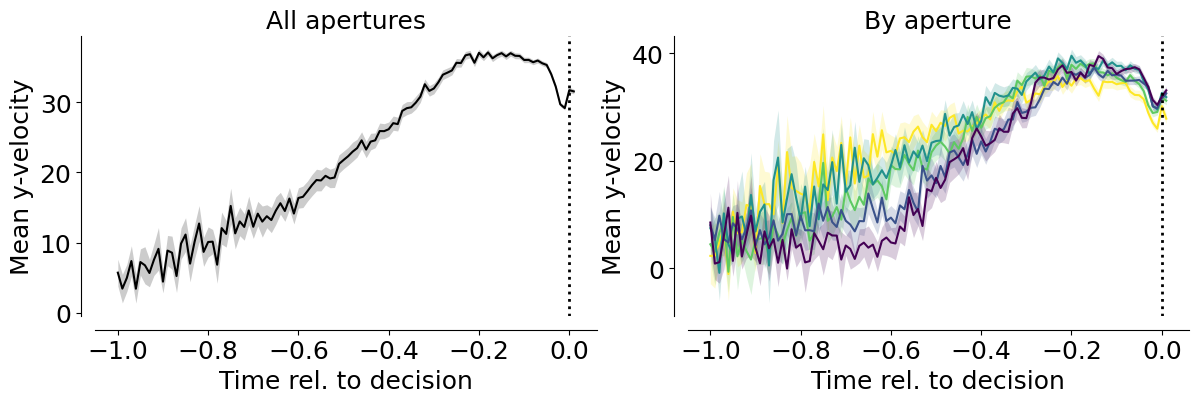

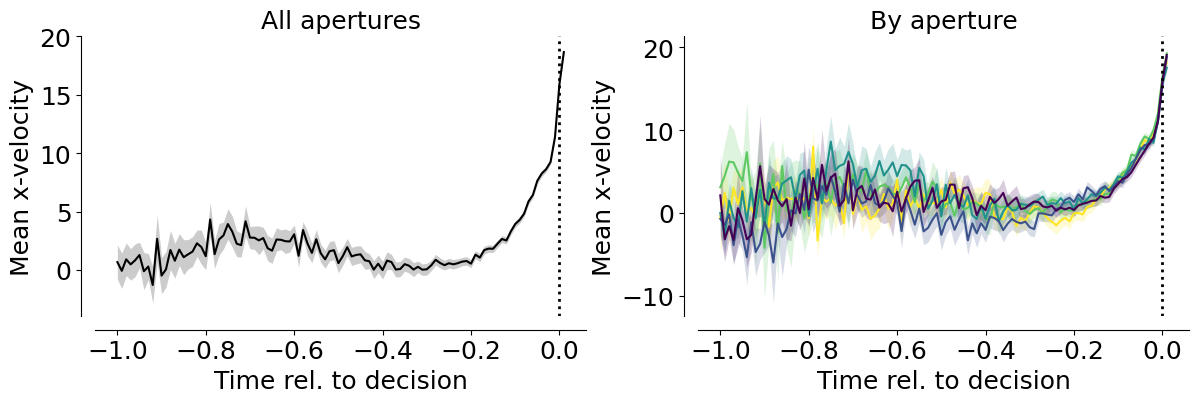

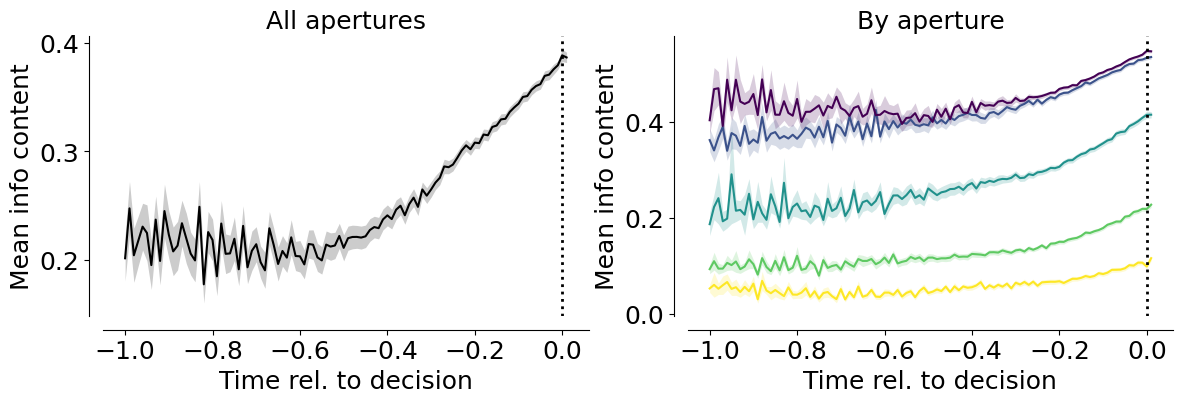

In [39]:
# Average velocity/info_gain around decision point
bin_size = 0.01
pre_window = 1
post_window = 0.02

dp_all = decision_points[["dataset", "aperture", "trial", "time_in_sec"]].rename(
    columns={"time_in_sec": "decision_tl"}
)

df_all = interpolated_df.merge(
    dp_all,
    on=["dataset", "aperture", "trial"],
    how="inner",
).copy()

df_all["t_rel"] = df_all["time_in_sec"] - df_all["decision_tl"]
df_all = df_all[(df_all.t_rel >= -pre_window) & (df_all.t_rel <= post_window)]

bins = np.arange(-pre_window, post_window + bin_size, bin_size)
df_all["t_bin"] = pd.cut(df_all.t_rel, bins=bins, labels=bins[:-1])

def _bin_mean_sem(frame, value_col):
    binned = (
        frame.groupby(["aperture", "t_bin"])[value_col]
        .agg(["mean", "sem"])
        .reset_index()
    )
    binned["t_bin"] = binned["t_bin"].astype(float)
    return binned

metrics = [
    {
        "col": "velocity_y",
        "ylabel": "Mean y-velocity",
        "file": "figure4_velocity_around_decision.svg",
    },
    {
        "col": "velocity_x_fliped",
        "ylabel": "Mean x-velocity",
        "file": "figure4_velocity_x_around_decision.svg",
    },
    {
        "col": "info_gain",
        "ylabel": "Mean info content",
        "file": "figure4_info_gain_around_decision.svg",
    },
]

binned_by_metric = {}
for metric in metrics:
    value_col = metric["col"]
    binned = _bin_mean_sem(df_all, value_col)
    binned_by_metric[value_col] = binned
    
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

    # Overall
    overall = (
        df_all.groupby("t_bin")[value_col]
        .agg(["mean", "sem"])
        .reset_index()
    )
    overall["t_bin"] = overall["t_bin"].astype(float)
    axes[0].plot(overall.t_bin, overall["mean"], color="black", linewidth=1.5)
    axes[0].fill_between(
        overall.t_bin,
        overall["mean"] - overall["sem"],
        overall["mean"] + overall["sem"],
        color="black",
        alpha=0.2,
        linewidth=0,
    )
    axes[0].axvline(0, color="black", linestyle=":", linewidth=2)
    axes[0].set_title("All apertures")
    axes[0].set_ylabel(metric["ylabel"])
    axes[0].set_xlabel("Time rel. to decision")
    sns.despine(ax=axes[0])

    # By aperture
    for color, (idx, ap) in zip(plotting.colors_multi_aperture, enumerate(sorted(df_all.aperture.unique()))):
        ap_df = binned[binned.aperture == ap]
        axes[1].plot(ap_df.t_bin, ap_df["mean"], color=color, linewidth=1.5, label=f"Aperture {ap}")
        axes[1].fill_between(
            ap_df.t_bin,
            ap_df["mean"] - ap_df["sem"],
            ap_df["mean"] + ap_df["sem"],
            color=color,
            alpha=0.2,
            linewidth=0,
        )
    axes[1].axvline(0, color="black", linestyle=":", linewidth=2)
    axes[1].set_title("By aperture")
    axes[1].set_xlabel("Time rel. to decision")
    axes[1].set_ylabel(metric["ylabel"])
    sns.despine(ax=axes[1])

    plt.tight_layout()
    sns.despine(offset=10)
    plt.savefig(save_fig_path + metric["file"])


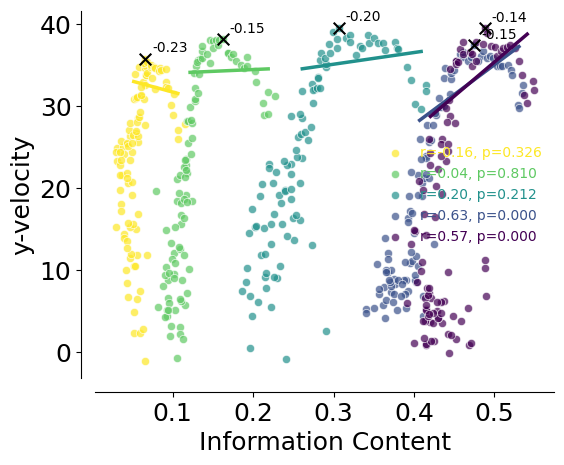

In [40]:
# Correlation between velocity and info gain (binned means)
vel_binned = binned_by_metric["velocity_y"]
info_binned = binned_by_metric["info_gain"]
corr_df = vel_binned.merge(
    info_binned,
    on=["aperture", "t_bin"],
    suffixes=("_vel", "_info"),
)

# Define your correlation window here
corr_window = (-0.4, 0.0)

fig, ax = plt.subplots(1, 1, figsize=(6, 5))
divider = make_axes_locatable(ax)
apertures_sorted = sorted(corr_df.aperture.unique())


for color, (i, ap) in zip(plotting.colors_multi_aperture, enumerate(apertures_sorted)):
    # Full data for the scatter plot
    ap_df = corr_df[corr_df.aperture == ap].dropna(subset=["mean_info", "mean_vel"])
    if ap_df.empty:
        continue
    
    # Find the row with the maximum velocity for this aperture
    max_row = ap_df.loc[ap_df["mean_vel"].idxmax()]
    max_x = max_row["mean_info"]
    max_y = max_row["mean_vel"]
    max_time = max_row["t_bin"]
    
    ax.scatter(max_x, max_y, marker='x', s=70, color='black', 
                zorder=10)
    ax.annotate(
        f"{max_time:.2f}", 
        xy=(max_x, max_y), 
        xytext=(5, 5), 
        textcoords='offset points',
        fontsize=10,
    )
    
    # Subset data for Pearson Correlation and Regression
    mask = (ap_df.t_bin >= corr_window[0]) & (ap_df.t_bin <= corr_window[1])
    stat_df = ap_df[mask]
    
    if not stat_df.empty:
        r_coeff, p_val = pearsonr(stat_df["mean_info"], stat_df["mean_vel"])
        label_str = f"r={r_coeff:.2f}, p={p_val:.3f}"
        
        # Plot regression line ONLY for the correlation window
        slope, intercept = np.polyfit(stat_df["mean_info"], stat_df["mean_vel"], 1)
        x_range = np.linspace(stat_df["mean_info"].min(), stat_df["mean_info"].max(), 10)
        ax.plot(x_range, slope * x_range + intercept, 
                color=color, linewidth=2.5, zorder=5)

    # Plot ALL scatter points
    sc = ax.scatter(
        ap_df["mean_info"],
        ap_df["mean_vel"],
        c=color,
        s=35,
        linewidths=0.6,
        label=label_str,
        edgecolor="white",
        alpha=0.7
    )

ax.set_xlabel("Information Content")
ax.set_ylabel("y-velocity")
leg = ax.legend(frameon=False)

for i, text in enumerate(leg.get_texts()):
    ap_key = apertures_sorted[i]
    text.set_color(plotting.colors_multi_aperture[i])

sns.despine(offset=10)
plt.tight_layout(pad=2.0)

plt.savefig(save_fig_path + "figure5_info_velocity_correlation_y.svg", transparent=True)

## Investigating first test session

In [41]:
interpolated_df["date"] = pd.to_datetime(interpolated_df["dataset"].str.split("_").str[1])
interpolated_df.sort_values(by=["mouse_name", "date"], inplace=True)

In [42]:
import copy
temp_interpolated_df = copy.deepcopy(interpolated_df)

temp_interpolated_df = temp_interpolated_df[temp_interpolated_df.mouse_name != "J731"]
temp_interpolated_df["y"] = temp_interpolated_df["y"]
first_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').first()["dataset"]
second_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').apply(lambda x: x.iloc[1])["dataset"]

/tmp/ipykernel_83567/1257764120.py:7: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  second_datasets = temp_interpolated_df[(temp_interpolated_df.trial == 20) & (temp_interpolated_df.trial_length == 0.0)].groupby('mouse_name').apply(lambda x: x.iloc[1])["dataset"]


In [43]:
# and for decision points
first_decision_points = decision_points[decision_points.dataset.isin(first_datasets)]
#first_decision_points = first_decision_points[~first_decision_points.mouse_name.isin(["J731"])]

Processing aperture: 12.0
trial_rewarded
Zero-shot baseline and SEM: 0.800 ± 0.067
distance_to_screen
Zero-shot baseline and SEM: 17.887 ± 0.190
Processing aperture: 8.48
trial_rewarded
Zero-shot baseline and SEM: 0.733 ± 0.067
distance_to_screen
Zero-shot baseline and SEM: 18.845 ± 0.666
Processing aperture: 6.0
trial_rewarded
Zero-shot baseline and SEM: 0.900 ± 0.100
distance_to_screen
Zero-shot baseline and SEM: 19.533 ± 0.016
Processing aperture: 4.2
trial_rewarded
Zero-shot baseline and SEM: 0.767 ± 0.100
distance_to_screen
Zero-shot baseline and SEM: 16.973 ± 0.778
Processing aperture: 3.0
trial_rewarded
Zero-shot baseline and SEM: 0.533 ± 0.133
distance_to_screen
Zero-shot baseline and SEM: 16.332 ± 0.102


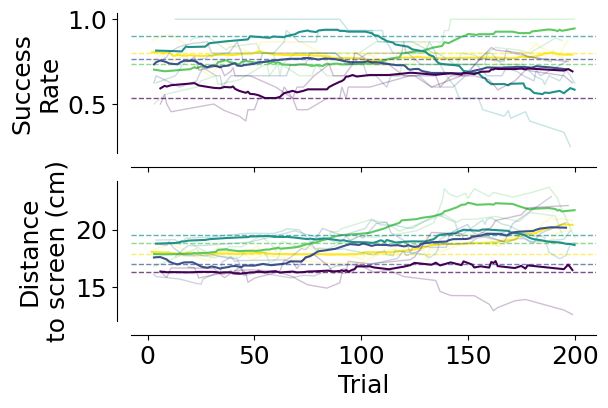

In [44]:
fig, ax = plt.subplots(2, 1, figsize=(6, 4), sharex=True)

window_size = 15
n_trials = 200

for aperture, color in zip(first_decision_points.aperture.unique(), plotting.colors_multi_aperture):
    print(f"Processing aperture: {aperture}")
    print("trial_rewarded")
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "trial_rewarded", 
                                        ax=ax[0],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False,
                                        print_zero_shot=True)
    print("distance_to_screen")
    plotting.plot_mouse_trial_lineplot(first_decision_points[(first_decision_points.aperture==aperture) & (first_decision_points.trial <= n_trials)], 
                                       "distance_to_screen",
                                        ax=ax[1],
                                        rolling_window=window_size,
                                        color=color,
                                        normalize=False,
                                        print_zero_shot=True)

ax[0].set_title("")
ax[1].set_title("")
ax[0].set_xlabel("")

ax[0].set_ylabel("Success\nRate")
ax[1].set_ylabel("Distance\nto screen (cm)")

for ax in ax.flatten():
    sns.despine(offset=10, ax=ax)
    
plt.savefig(save_fig_path + "figure5_first_session.svg", transparent=True, bbox_inches="tight")